# PRAICP-1010: Image Classification with 10 Categories

## Project Information
- Organization: DataMites
- Project ID: PRAICP-1010
- Domain: Data Science
- Project Type: Deep Learning / Computer Vision

## Business Objective
Develop a deep learning model capable of classifying images
into 10 different object categories.

## Project Approach
1. Dataset Collection and Inspection
2. Exploratory Data Analysis
3. Image Preprocessing
4. CNN Model Development
5. Model Training and Comparison
6. Model Evaluation
7. Prediction Testing
8. Model Saving
9. Final Project Documentation

## Evaluation
The models will be evaluated using accuracy, precision,
recall, F1-score, confusion matrix and other suitable metrics.


In [1]:
import os
import sys
import zipfile
import shutil
import random
import pathlib

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

print("Python Version:", sys.version)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

print("\nBasic libraries imported successfully!")

Python Version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
NumPy Version: 2.3.5
Pandas Version: 2.3.3

Basic libraries imported successfully!


In [3]:
from pathlib import Path
import os

# Project directory
PROJECT_DIR = Path.cwd()

# Actual extracted dataset location
DATASET_DIR = Path(
    r"C:\Users\prana\Downloads\imagenet-subset-10"
)

# Verify dataset path
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}"
    )

print("Dataset found successfully!")
print("Dataset path:", DATASET_DIR)

# Display folder structure
print("\nDataset folder structure:\n")

for root, dirs, files in os.walk(DATASET_DIR):
    level = len(Path(root).relative_to(DATASET_DIR).parts)

    if level > 2:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{Path(root).name}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

print("\nDataset inspection completed!")

Dataset found successfully!
Dataset path: C:\Users\prana\Downloads\imagenet-subset-10

Dataset folder structure:

imagenet-subset-10/
    imagenet subset/
        desc.txt
        train/
        val/

Dataset inspection completed!


# 2. Dataset Understanding

The dataset contains training and validation images.
We will inspect the dataset description and identify
the available image categories.

In [4]:
# Locate and read dataset description

description_file = DATASET_DIR / "imagenet subset" / "desc.txt"

if description_file.exists():
    with open(description_file, "r", encoding="utf-8") as file:
        description = file.read()

    print("DATASET DESCRIPTION\n")
    print(description)
else:
    print("desc.txt file not found.")

DATASET DESCRIPTION

 	imagenette_map = { 
    "n01440764" : "tench",
    "n02102040" : "springer",
    "n02979186" : "casette_player",
    "n03000684" : "chain_saw",
    "n03028079" : "church",
    "n03394916" : "French_horn",
    "n03417042" : "garbage_truck",
    "n03425413" : "gas_pump",
    "n03445777" : "golf_ball",
    "n03888257" : "parachute"
}


In [5]:
# Define dataset directories

DATA_ROOT = DATASET_DIR / "imagenet subset"

TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR = DATA_ROOT / "val"

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# Verify directories
print("Training directory exists:", TRAIN_DIR.exists())
print("Validation directory exists:", VAL_DIR.exists())

if not TRAIN_DIR.exists() or not VAL_DIR.exists():
    raise FileNotFoundError(
        "Training or validation directory is missing."
    )

# Function to count images in each category
def inspect_categories(folder):

    category_counts = {}

    for category_dir in sorted(folder.iterdir()):

        if category_dir.is_dir():

            image_files = [
                file for file in category_dir.rglob("*")
                if file.is_file()
                and file.suffix.lower() in IMAGE_EXTENSIONS
            ]

            category_counts[category_dir.name] = len(image_files)

    return category_counts


# Inspect training and validation datasets
train_counts = inspect_categories(TRAIN_DIR)
val_counts = inspect_categories(VAL_DIR)

# Display results
print("\nTRAINING DATASET")
print("-" * 40)

for category, count in train_counts.items():
    print(f"{category}: {count} images")

print("\nVALIDATION DATASET")
print("-" * 40)

for category, count in val_counts.items():
    print(f"{category}: {count} images")


# Dataset summary
print("\nDATASET SUMMARY")
print("-" * 40)

print("Training categories:", len(train_counts))
print("Validation categories:", len(val_counts))

print("Total training images:", sum(train_counts.values()))
print("Total validation images:", sum(val_counts.values()))

print(
    "Total images:",
    sum(train_counts.values()) + sum(val_counts.values())
)

Training directory exists: True
Validation directory exists: True

TRAINING DATASET
----------------------------------------
n01440764: 963 images
n02102040: 955 images
n02979186: 993 images
n03000684: 858 images
n03028079: 941 images
n03394916: 956 images
n03417042: 961 images
n03425413: 931 images
n03445777: 951 images
n03888257: 960 images

VALIDATION DATASET
----------------------------------------
n01440764: 387 images
n02102040: 395 images
n02979186: 357 images
n03000684: 386 images
n03028079: 409 images
n03394916: 394 images
n03417042: 389 images
n03425413: 419 images
n03445777: 399 images
n03888257: 390 images

DATASET SUMMARY
----------------------------------------
Training categories: 10
Validation categories: 10
Total training images: 9469
Total validation images: 3925
Total images: 13394


In [6]:
# Create summary DataFrame

dataset_summary = pd.DataFrame({
    "Category": list(train_counts.keys()),
    "Training Images": [
        train_counts.get(category, 0)
        for category in train_counts
    ],
    "Validation Images": [
        val_counts.get(category, 0)
        for category in train_counts
    ]
})

dataset_summary["Total Images"] = (
    dataset_summary["Training Images"]
    + dataset_summary["Validation Images"]
)

display(dataset_summary)

print("\nOverall dataset statistics:")

display(
    dataset_summary[
        ["Training Images", "Validation Images", "Total Images"]
    ].sum().to_frame("Total")
)

,Category,Training Images,Validation Images,Total Images
0,n01440764,963,387,1350
1,n02102040,955,395,1350
2,n02979186,993,357,1350
3,n03000684,858,386,1244
4,n03028079,941,409,1350
5,n03394916,956,394,1350
6,n03417042,961,389,1350
7,n03425413,931,419,1350
8,n03445777,951,399,1350
9,n03888257,960,390,1350



Overall dataset statistics:


,Total
Training Images,9469
Validation Images,3925
Total Images,13394


# Correct dataset summary and class distribution

In [7]:
# Rebuild the summary directly from the original dictionaries

categories = sorted(set(train_counts) | set(val_counts))

dataset_summary = pd.DataFrame({
    "Category": categories,
    "Training Images": [train_counts.get(c, 0) for c in categories],
    "Validation Images": [val_counts.get(c, 0) for c in categories]
})

dataset_summary["Total Images"] = (
    dataset_summary["Training Images"]
    + dataset_summary["Validation Images"]
)

display(dataset_summary)

print("\nTotal training images:", dataset_summary["Training Images"].sum())
print("Total validation images:", dataset_summary["Validation Images"].sum())
print("Total images:", dataset_summary["Total Images"].sum())
print("Number of categories:", len(categories))

,Category,Training Images,Validation Images,Total Images
0,n01440764,963,387,1350
1,n02102040,955,395,1350
2,n02979186,993,357,1350
3,n03000684,858,386,1244
4,n03028079,941,409,1350
5,n03394916,956,394,1350
6,n03417042,961,389,1350
7,n03425413,931,419,1350
8,n03445777,951,399,1350
9,n03888257,960,390,1350



Total training images: 9469
Total validation images: 3925
Total images: 13394
Number of categories: 10


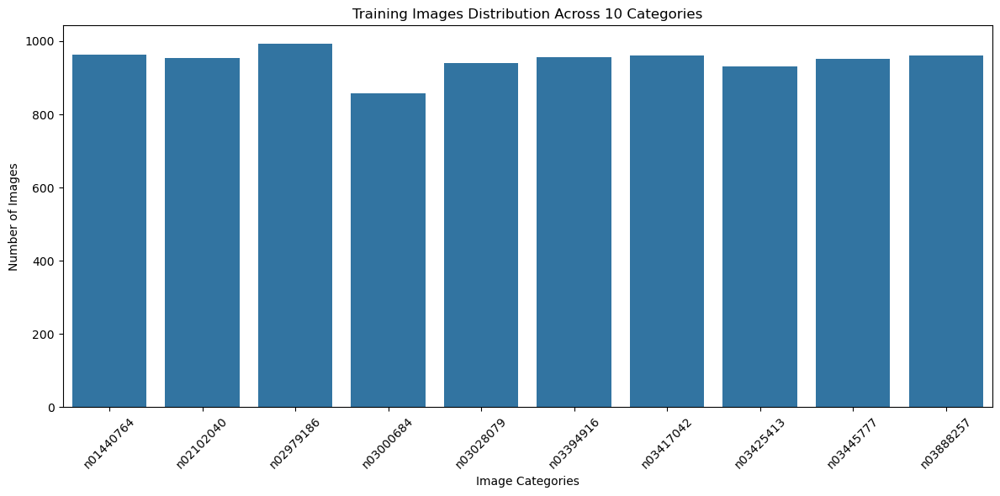

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=dataset_summary,
    x="Category",
    y="Training Images"
)

plt.title("Training Images Distribution Across 10 Categories")
plt.xlabel("Image Categories")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
print("CLASS IMBALANCE ANALYSIS")
print("-" * 45)

max_images = dataset_summary["Total Images"].max()
min_images = dataset_summary["Total Images"].min()

print("Maximum images in a category:", max_images)
print("Minimum images in a category:", min_images)

imbalance_ratio = max_images / min_images

print("Class imbalance ratio:", round(imbalance_ratio, 3))

if imbalance_ratio <= 1.5:
    print("Dataset has relatively balanced classes.")
else:
    print("Dataset has noticeable class imbalance.")

CLASS IMBALANCE ANALYSIS
---------------------------------------------
Maximum images in a category: 1350
Minimum images in a category: 1244
Class imbalance ratio: 1.085
Dataset has relatively balanced classes.


# Image quality and image inspection

In [13]:
# Collect all training and validation image paths

image_records = []

for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Validation", VAL_DIR)
]:
    for category_dir in sorted(split_dir.iterdir()):

        if category_dir.is_dir():

            for image_path in category_dir.rglob("*"):

                if (
                    image_path.is_file()
                    and image_path.suffix.lower() in IMAGE_EXTENSIONS
                ):
                    image_records.append({
                        "Split": split_name,
                        "Category": category_dir.name,
                        "Image_Path": image_path
                    })

image_df = pd.DataFrame(image_records)

print("Total images collected:", len(image_df))
print("\nImages by split:")
print(image_df["Split"].value_counts())

print("\nImages by category:")
display(
    image_df.groupby(["Split", "Category"])
    .size()
    .reset_index(name="Image Count")
)

Total images collected: 13394

Images by split:
Split
Train         9469
Validation    3925
Name: count, dtype: int64

Images by category:


,Split,Category,Image Count
0,Train,n01440764,963
1,Train,n02102040,955
2,Train,n02979186,993
3,Train,n03000684,858
4,Train,n03028079,941
5,Train,n03394916,956
6,Train,n03417042,961
7,Train,n03425413,931
8,Train,n03445777,951
9,Train,n03888257,960


In [14]:
# Inspect a random sample of up to 500 images

sample_size = min(500, len(image_df))

dimension_sample = image_df.sample(
    n=sample_size,
    random_state=42
)

image_properties = []

for image_path in dimension_sample["Image_Path"]:

    try:
        with Image.open(image_path) as img:

            image_properties.append({
                "Width": img.width,
                "Height": img.height,
                "Format": img.format,
                "Mode": img.mode
            })

    except Exception as error:
        print("Unable to inspect:", image_path, error)

image_properties_df = pd.DataFrame(image_properties)

print("Successfully inspected images:", len(image_properties_df))

print("\nImage formats:")
display(image_properties_df["Format"].value_counts())

print("\nImage color modes:")
display(image_properties_df["Mode"].value_counts())

print("\nImage dimensions statistics:")
display(
    image_properties_df[["Width", "Height"]].describe()
)

print("\nUnique image dimensions:")
print(
    image_properties_df.groupby(
        ["Width", "Height"]
    ).size().sort_values(ascending=False).head(15)
)

Successfully inspected images: 500

Image formats:


Format
JPEG    500
Name: count, dtype: int64


Image color modes:


Mode
RGB    494
L        6
Name: count, dtype: int64


Image dimensions statistics:


,Width,Height
count,500.00000,500.000000
mean,458.87800,388.012000
std,162.84113,143.633342
min,82.00000,32.000000
25%,375.00000,333.000000
50%,500.00000,375.000000
75%,500.00000,500.000000
max,1600.00000,1208.000000



Unique image dimensions:
Width  Height
500    375       116
       333        47
375    500        33
333    500        16
500    334        15
       332         9
       500         7
       400         6
       377         5
       335         4
200    150         4
334    500         4
320    240         4
400    500         3
500    367         3
dtype: int64


In [15]:
# Check all images for readability

corrupted_images = []
valid_images = 0

for image_path in image_df["Image_Path"]:

    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_images += 1

    except Exception:
        corrupted_images.append(str(image_path))

print("Total images checked:", len(image_df))
print("Valid images:", valid_images)
print("Corrupted or unreadable images:", len(corrupted_images))

if corrupted_images:
    print("\nCorrupted image paths:")
    for path in corrupted_images[:20]:
        print(path)
else:
    print("\nAll images passed the image integrity check!")

Total images checked: 13394
Valid images: 13394
Corrupted or unreadable images: 0

All images passed the image integrity check!


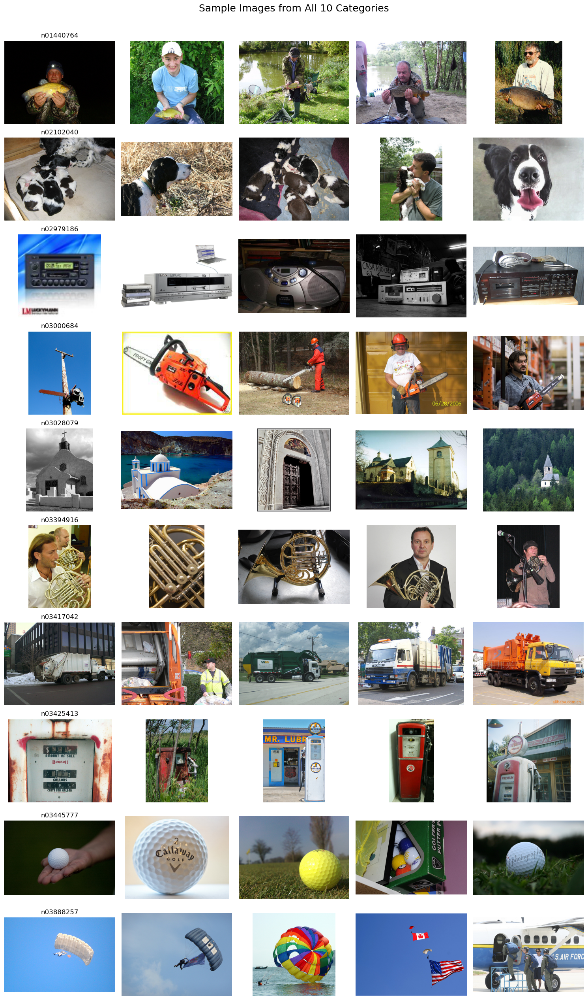

In [16]:
# Display 5 sample images from each category

categories = sorted(train_counts.keys())

fig, axes = plt.subplots(
    nrows=len(categories),
    ncols=5,
    figsize=(15, 25)
)

for row, category in enumerate(categories):

    category_images = image_df[
        (image_df["Split"] == "Train") &
        (image_df["Category"] == category)
    ]["Image_Path"].tolist()

    selected_images = random.Random(42).sample(
        category_images,
        min(5, len(category_images))
    )

    for col in range(5):

        ax = axes[row, col]

        if col < len(selected_images):

            with Image.open(selected_images[col]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(category if col == 0 else "")
        else:
            ax.axis("off")

        ax.axis("off")

plt.suptitle(
    "Sample Images from All 10 Categories",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

# Identify the 10 object categories

In [17]:
# Read the dataset description file

description_file = DATA_ROOT / "desc.txt"

with open(description_file, "r", encoding="utf-8") as file:
    desc_text = file.read()

print("DATASET CATEGORY DESCRIPTIONS")
print("=" * 60)
print(desc_text)

DATASET CATEGORY DESCRIPTIONS
 	imagenette_map = { 
    "n01440764" : "tench",
    "n02102040" : "springer",
    "n02979186" : "casette_player",
    "n03000684" : "chain_saw",
    "n03028079" : "church",
    "n03394916" : "French_horn",
    "n03417042" : "garbage_truck",
    "n03425413" : "gas_pump",
    "n03445777" : "golf_ball",
    "n03888257" : "parachute"
}


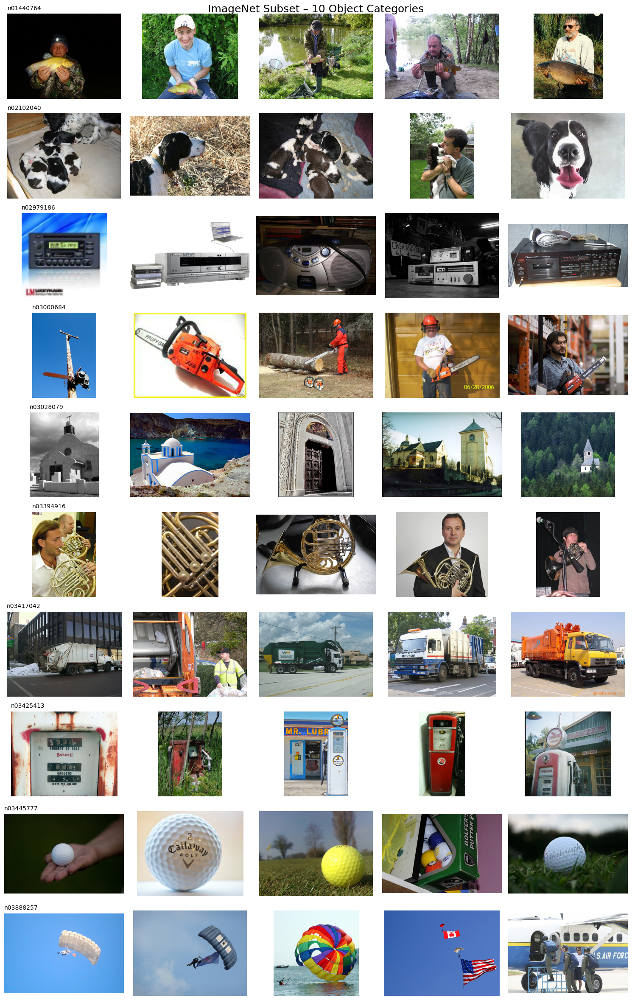

In [18]:
import matplotlib.pyplot as plt
from PIL import Image
import random

categories = sorted(train_counts.keys())

fig, axes = plt.subplots(
    10, 5,
    figsize=(15, 24)
)

for row, category in enumerate(categories):

    category_images = image_df[
        (image_df["Split"] == "Train") &
        (image_df["Category"] == category)
    ]["Image_Path"].tolist()

    selected = random.Random(42).sample(
        category_images, 5
    )

    for col, image_path in enumerate(selected):

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(
                category,
                loc="left",
                fontsize=10
            )

plt.suptitle(
    "ImageNet Subset – 10 Object Categories",
    fontsize=18
)

plt.tight_layout()
plt.show()

# Prepare the CNN environment`

In [19]:
import importlib.util

libraries = [
    "tensorflow",
    "keras",
    "sklearn",
    "PIL",
    "matplotlib",
    "seaborn"
]

print("LIBRARY AVAILABILITY")
print("-" * 40)

for library in libraries:

    available = importlib.util.find_spec(library) is not None

    print(
        library,
        ": Installed" if available else ": Not Installed"
    )

LIBRARY AVAILABILITY
----------------------------------------
tensorflow : Installed
keras : Installed
sklearn : Installed
PIL : Installed
matplotlib : Installed
seaborn : Installed


## Official category mapping

In [20]:
# Official ImageNet category mapping

class_mapping = {
    "n01440764": "Tench",
    "n02102040": "Springer",
    "n02979186": "Cassette Player",
    "n03000684": "Chainsaw",
    "n03028079": "Church",
    "n03394916": "French Horn",
    "n03417042": "Garbage Truck",
    "n03425413": "Gas Pump",
    "n03445777": "Golf Ball",
    "n03888257": "Parachute"
}

# Display category mapping

class_mapping_df = pd.DataFrame(
    list(class_mapping.items()),
    columns=["ImageNet ID", "Object Category"]
)

display(class_mapping_df)

print("Total categories:", len(class_mapping))

,ImageNet ID,Object Category
0,n01440764,Tench
1,n02102040,Springer
2,n02979186,Cassette Player
3,n03000684,Chainsaw
4,n03028079,Church
5,n03394916,French Horn
6,n03417042,Garbage Truck
7,n03425413,Gas Pump
8,n03445777,Golf Ball
9,n03888257,Parachute


Total categories: 10


In [21]:
import tensorflow as tf
import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("\nGPU devices:", gpus if gpus else "No GPU detected")
print("\nCPU devices:", tf.config.list_physical_devices("CPU"))

TensorFlow version: 2.21.0
Keras version: 3.15.1

GPU devices: No GPU detected

CPU devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [22]:
import platform
import psutil

print("Processor:", platform.processor())
print("CPU cores:", psutil.cpu_count(logical=False))
print("Logical CPU cores:", psutil.cpu_count(logical=True))

memory = psutil.virtual_memory()

print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")

Processor: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
CPU cores: 4
Logical CPU cores: 8
Total RAM: 15.82 GB
Available RAM: 3.6 GB


## Define preprocessing configuration

In [23]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Image configuration
IMG_HEIGHT = 160
IMG_WIDTH = 160
BATCH_SIZE = 16
NUM_CLASSES = 10

# Dataset directories
TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR = DATA_ROOT / "val"

# CPU configuration
print("TensorFlow:", tf.__version__)
print("Image size:", IMG_HEIGHT, "x", IMG_WIDTH)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

print("\nPreprocessing configuration initialized!")

TensorFlow: 2.21.0
Image size: 160 x 160
Batch size: 16
Number of classes: 10

Preprocessing configuration initialized!


In [24]:
# Load training dataset

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    labels="inferred",
    label_mode="int",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True,
    seed=SEED
)

# Load validation dataset

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(VAL_DIR),
    labels="inferred",
    label_mode="int",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

# Save class names in the correct numerical order
class_names = train_ds.class_names

print("\nClass names:")
print(class_names)

print("\nTraining batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Found 9469 files belonging to 10 classes.
Found 3925 files belonging to 10 classes.

Class names:
['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']

Training batches: 592
Validation batches: 246


## Configure efficient CPU data loading

In [25]:
# Configure dataset threading and prefetching

options = tf.data.Options()

options.threading.private_threadpool_size = 4
options.threading.max_intra_op_parallelism = 2

train_ds = train_ds.with_options(options)
val_ds = val_ds.with_options(options)

# Prefetch one batch to limit memory usage
train_ds = train_ds.prefetch(1)
val_ds = val_ds.prefetch(1)

print("CPU-friendly data pipeline configured!")
print("Training and validation datasets are ready.")

CPU-friendly data pipeline configured!
Training and validation datasets are ready.


In [26]:
# Verify TensorFlow category ordering

print("CATEGORY AND LABEL MAPPING")
print("-" * 45)

for index, category_id in enumerate(class_names):

    object_name = class_mapping.get(
        category_id,
        "Unknown"
    )

    print(
        f"Label {index}: {category_id} -> {object_name}"
    )

# Check that all expected categories are present
assert len(class_names) == NUM_CLASSES
assert set(class_names) == set(class_mapping.keys())

print("\nAll 10 categories verified successfully!")

CATEGORY AND LABEL MAPPING
---------------------------------------------
Label 0: n01440764 -> Tench
Label 1: n02102040 -> Springer
Label 2: n02979186 -> Cassette Player
Label 3: n03000684 -> Chainsaw
Label 4: n03028079 -> Church
Label 5: n03394916 -> French Horn
Label 6: n03417042 -> Garbage Truck
Label 7: n03425413 -> Gas Pump
Label 8: n03445777 -> Golf Ball
Label 9: n03888257 -> Parachute

All 10 categories verified successfully!


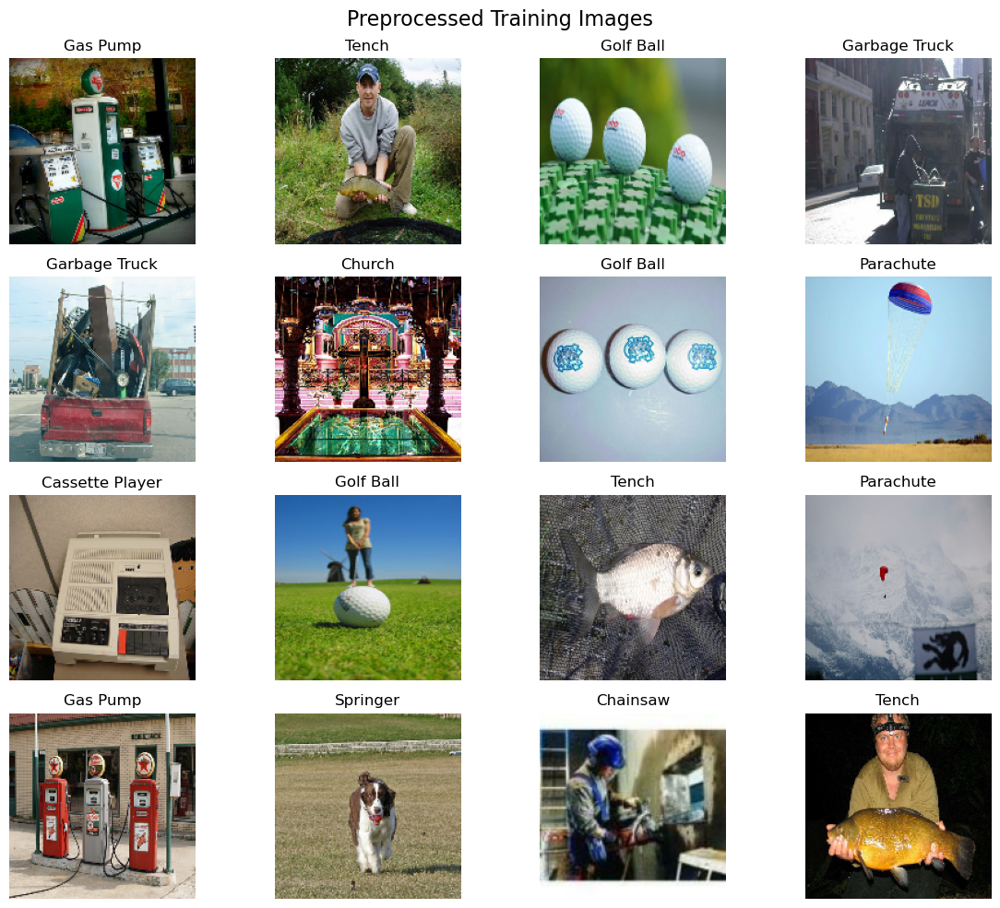

In [27]:
# Display a batch of preprocessed images

plt.figure(figsize=(12, 10))

for images, labels in train_ds.take(1):

    for i in range(min(16, len(images))):

        plt.subplot(4, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_id = int(labels[i].numpy())
        category_id = class_names[label_id]

        object_name = class_mapping[category_id]

        plt.title(object_name)
        plt.axis("off")

plt.suptitle(
    "Preprocessed Training Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Data augmentation

In [28]:
# Create augmentation layers

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10)
    ],
    name="data_augmentation"
)

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


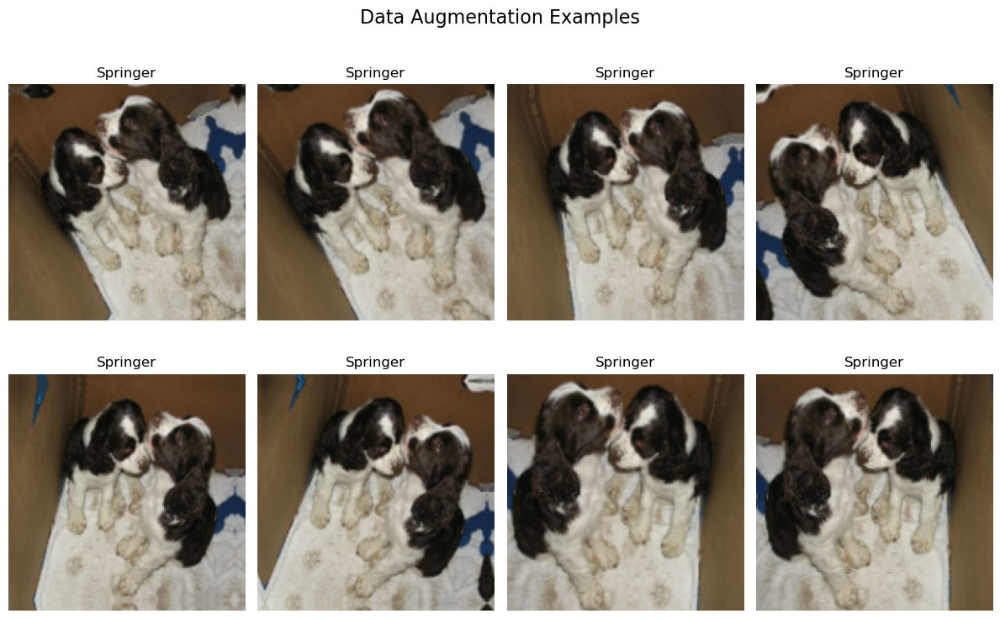

In [29]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    sample_image = images[0]
    sample_label = int(labels[0].numpy())

    for i in range(8):

        augmented_image = data_augmentation(
            tf.expand_dims(sample_image, axis=0),
            training=True
        )[0]

        plt.subplot(2, 4, i + 1)

        plt.imshow(
            tf.clip_by_value(
                augmented_image / 255.0,
                0,
                1
            )
        )

        plt.title(class_mapping[class_names[sample_label]])
        plt.axis("off")

plt.suptitle("Data Augmentation Examples", fontsize=16)
plt.tight_layout()
plt.show()

In [30]:
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    augmented_batch = data_augmentation(
        images,
        training=True
    )

    print("\nAugmented batch shape:", augmented_batch.shape)

Image batch shape: (16, 160, 160, 3)
Label batch shape: (16,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0

Augmented batch shape: (16, 160, 160, 3)


# Build your first CNN model

In [31]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    # Data augmentation
    data_augmentation,

    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1./255),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # 10-category output
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="Image_Classification_CNN")

print("CNN model created successfully!")

CNN model created successfully!


In [32]:
cnn_model.summary()

Model: "Image_Classification_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 160, 160, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 80, 80, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 80, 80, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 40, 40, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 40, 40, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")
print("Optimizer: Adam")
print("Loss: Sparse Categorical Crossentropy")
print("Metric: Accuracy")

CNN model compiled successfully!
Optimizer: Adam
Loss: Sparse Categorical Crossentropy
Metric: Accuracy


In [34]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath=str(PROJECT_DIR / "models" / "best_cnn_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


# Train the CNN model

In [35]:
import time

start_time = time.time()

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

end_time = time.time()

training_time = end_time - start_time

print("\nCNN training completed!")
print("Total training time:", round(training_time / 60, 2), "minutes")

Epoch 1/10


C:\Users\prana\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


592/592 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.2209 - loss: 2.1032
Epoch 1: val_loss improved from None to 2.13140, saving model to C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_cnn_model.keras

Epoch 1: finished saving model to C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_cnn_model.keras
592/592 ━━━━━━━━━━━━━━━━━━━━ 155s 258ms/step - accuracy: 0.2209 - loss: 2.1032 - val_accuracy: 0.2769 - val_loss: 2.1314 - learning_rate: 0.0010
Epoch 2/10
592/592 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.3367 - loss: 1.8688
Epoch 2: val_loss improved from 2.13140 to 1.91332, saving model to C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_cnn_model.keras

Epoch 2: finished saving model to C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_cnn_model.keras
592/592 ━━━━━━━━━━━━━━━━━━━━ 145s 245ms/step - 

In [36]:
training_results = pd.DataFrame(history.history)

display(training_results)

print("Best Training Accuracy:",
      round(max(history.history["accuracy"]) * 100, 2), "%")

print("Best Validation Accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")

print("Best Validation Loss:",
      round(min(history.history["val_loss"]), 4))

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.220931,2.103245,0.276943,2.131399,0.001
1,0.336678,1.868840,0.342675,1.913322,0.001
2,0.391488,1.741583,0.382675,1.889938,0.001
3,0.432886,1.649892,0.418089,1.806178,0.001
4,0.461823,1.583094,0.437962,1.783182,0.001
5,0.491604,1.517223,0.464713,1.656888,0.001
6,0.516528,1.449054,0.509299,1.535847,0.001
7,0.532897,1.409472,0.530701,1.482056,0.001
8,0.548421,1.353629,0.537834,1.457399,0.001
9,0.562678,1.328473,0.568408,1.355495,0.001


Best Training Accuracy: 56.27 %
Best Validation Accuracy: 56.84 %
Best Validation Loss: 1.3555


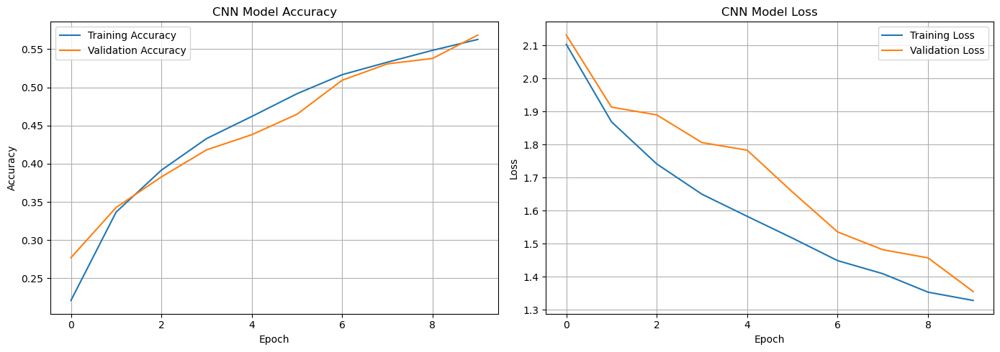

In [37]:
plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Generate predictions

In [38]:
import numpy as np

# Generate predictions on validation images
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_prob = cnn_model.predict(val_ds, verbose=1)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

print("\nPredictions generated successfully!")

246/246 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step
Actual labels shape: (3925,)
Predicted labels shape: (3925,)

Predictions generated successfully!


In [39]:
# Calculate evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("CNN VALIDATION PERFORMANCE")
print("=" * 40)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=[
        class_mapping[name] for name in class_names
    ],
    zero_division=0
))

CNN VALIDATION PERFORMANCE
Accuracy:  0.5684
Precision: 0.6003
Recall:    0.5673
F1-Score:  0.5608

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

          Tench       0.69      0.48      0.56       387
       Springer       0.77      0.41      0.54       395
Cassette Player       0.69      0.63      0.66       357
       Chainsaw       0.45      0.17      0.25       386
         Church       0.43      0.74      0.54       409
    French Horn       0.46      0.73      0.57       394
  Garbage Truck       0.55      0.65      0.60       389
       Gas Pump       0.51      0.62      0.56       419
      Golf Ball       0.71      0.54      0.61       399
      Parachute       0.76      0.70      0.73       390

       accuracy                           0.57      3925
      macro avg       0.60      0.57      0.56      3925
   weighted avg       0.60      0.57      0.56      3925



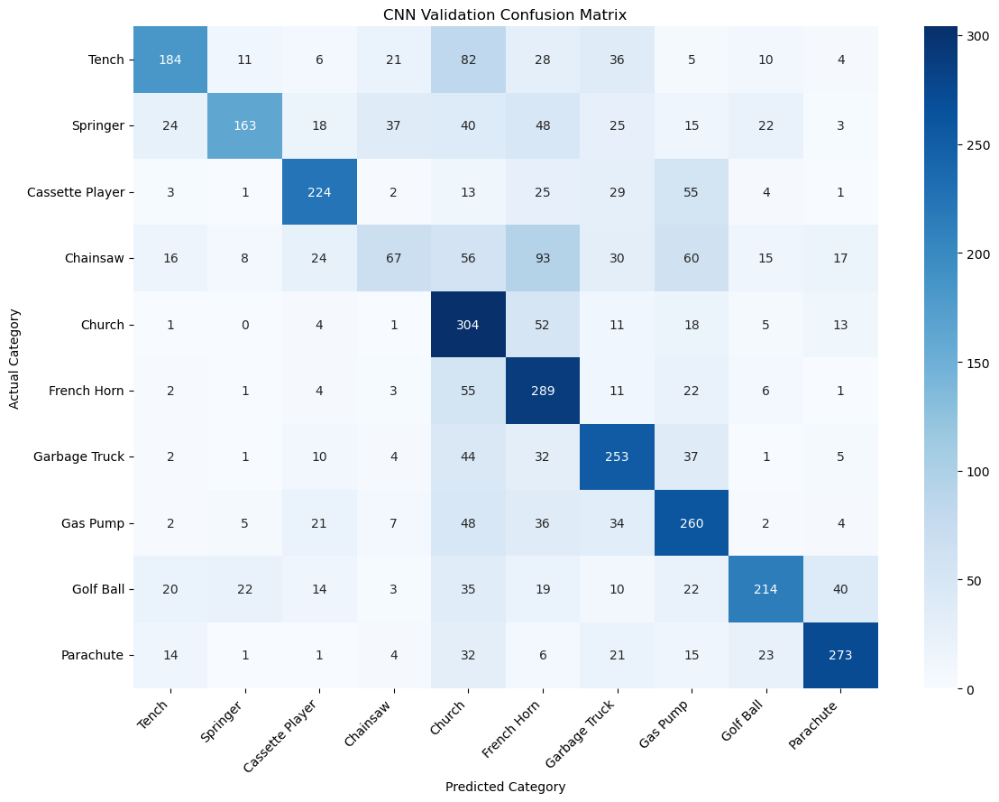

In [40]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        class_mapping[name] for name in class_names
    ],
    yticklabels=[
        class_mapping[name] for name in class_names
    ]
)

plt.title("CNN Validation Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

,Metric,Score
0,Accuracy,0.568408
1,Precision,0.600322
2,Recall,0.567317
3,F1-Score,0.560773


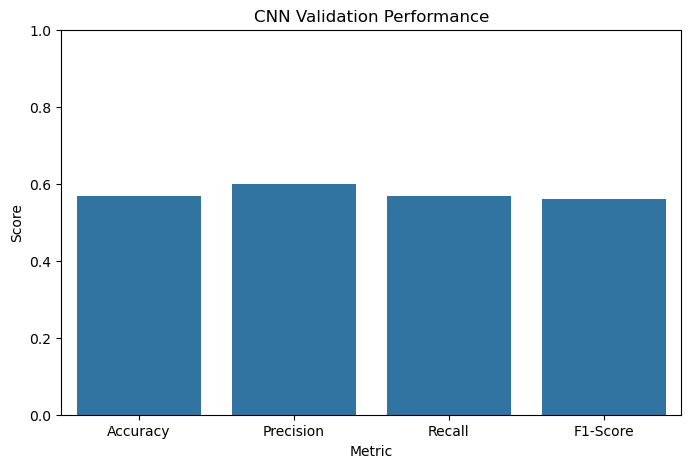

In [41]:
metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics_df)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Score"
)

plt.ylim(0, 1)
plt.title("CNN Validation Performance")
plt.ylabel("Score")
plt.show()

# Analyze correct and incorrect predictions

In [42]:
# Create prediction analysis DataFrame
prediction_df = pd.DataFrame({
    "Actual_Label": y_true,
    "Predicted_Label": y_pred,
    "Actual_Category": [
        class_mapping[class_names[i]] for i in y_true
    ],
    "Predicted_Category": [
        class_mapping[class_names[i]] for i in y_pred
    ],
    "Confidence": np.max(y_prob, axis=1)
})

prediction_df["Correct"] = (
    prediction_df["Actual_Label"] ==
    prediction_df["Predicted_Label"]
)

display(prediction_df.head(10))

,Actual_Label,Predicted_Label,Actual_Category,Predicted_Category,Confidence,Correct
0,0,3,Tench,Chainsaw,0.233972,False
1,0,6,Tench,Garbage Truck,0.198582,False
2,0,0,Tench,Tench,0.761809,True
3,0,0,Tench,Tench,0.414809,True
4,0,4,Tench,Church,0.705147,False
5,0,0,Tench,Tench,0.563038,True
6,0,2,Tench,Cassette Player,0.410763,False
7,0,0,Tench,Tench,0.567053,True
8,0,0,Tench,Tench,0.520935,True
9,0,0,Tench,Tench,0.783039,True


In [43]:
# Count correct and incorrect predictions

correct_count = prediction_df["Correct"].sum()
incorrect_count = (~prediction_df["Correct"]).sum()

print("Total validation images:", len(prediction_df))
print("Correct predictions:", correct_count)
print("Incorrect predictions:", incorrect_count)

print(
    "Validation accuracy:",
    round(correct_count / len(prediction_df) * 100, 2),
    "%"
)

Total validation images: 3925
Correct predictions: 2231
Incorrect predictions: 1694
Validation accuracy: 56.84 %


In [44]:
# Analyze errors by category

category_performance = (
    prediction_df.groupby("Actual_Category")
    .agg(
        Total_Images=("Correct", "count"),
        Correct_Predictions=("Correct", "sum")
    )
)

category_performance["Incorrect_Predictions"] = (
    category_performance["Total_Images"] -
    category_performance["Correct_Predictions"]
)

category_performance["Accuracy"] = (
    category_performance["Correct_Predictions"] /
    category_performance["Total_Images"]
)

category_performance = category_performance.sort_values(
    "Accuracy",
    ascending=False
)

display(category_performance)

,Total_Images,Correct_Predictions,Incorrect_Predictions,Accuracy
Actual_Category,,,,
Church,409,304,105,0.743276
French Horn,394,289,105,0.733503
Parachute,390,273,117,0.700000
Garbage Truck,389,253,136,0.650386
Cassette Player,357,224,133,0.627451
Gas Pump,419,260,159,0.620525
Golf Ball,399,214,185,0.536341
Tench,387,184,203,0.475452
Springer,395,163,232,0.412658


# Build MobileNetV2



In [46]:
# Load pretrained MobileNetV2

from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Pretrained layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step
MobileNetV2 loaded successfully!
Pretrained layers: 154
Trainable: False


In [47]:
# Build transfer learning model

transfer_model = keras.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    # Augmentation
    data_augmentation,

    # MobileNetV2 input preprocessing
    layers.Rescaling(scale=1./127.5, offset=-1),

    # Pretrained feature extractor
    base_model,

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="MobileNetV2_Transfer_Learning")

print("Transfer learning model created!")

Transfer learning model created!


In [48]:
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

Model: "MobileNetV2_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [49]:
transfer_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(PROJECT_DIR / "models" / "best_mobilenetv2.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=0.00001,
        verbose=1
    )
]

print("MobileNetV2 callbacks configured!")

MobileNetV2 callbacks configured!


# Train MobileNetV2

In [50]:
import time

mobilenet_start = time.time()

mobilenet_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=transfer_callbacks,
    verbose=1
)

mobilenet_time = time.time() - mobilenet_start

print("\nMobileNetV2 training completed!")
print("Training time:",
      round(mobilenet_time / 60, 2), "minutes")

Epoch 1/5


C:\Users\prana\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


592/592 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.8764 - loss: 0.4125
Epoch 1: val_loss improved from None to 0.06495, saving model to C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_mobilenetv2.keras

Epoch 1: finished saving model to C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_mobilenetv2.keras
592/592 ━━━━━━━━━━━━━━━━━━━━ 161s 264ms/step - accuracy: 0.8764 - loss: 0.4125 - val_accuracy: 0.9806 - val_loss: 0.0650 - learning_rate: 5.0000e-04
Epoch 2/5
592/592 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.9411 - loss: 0.1933
Epoch 2: val_loss improved from 0.06495 to 0.05660, saving model to C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_mobilenetv2.keras

Epoch 2: finished saving model to C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_mobilenetv2.keras
592/592 ━━━━━━━━━━━━━━━━━━━━ 156s 26

# Compare training results


In [51]:
mobilenet_val_accuracy = max(
    mobilenet_history.history["val_accuracy"]
)

print("Custom CNN best validation accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")

print("MobileNetV2 best validation accuracy:",
      round(mobilenet_val_accuracy * 100, 2), "%")

print("Custom CNN training time:",
      round(training_time / 60, 2), "minutes")

print("MobileNetV2 training time:",
      round(mobilenet_time / 60, 2), "minutes")

Custom CNN best validation accuracy: 56.84 %
MobileNetV2 best validation accuracy: 98.75 %
Custom CNN training time: 27.52 minutes
MobileNetV2 training time: 13.13 minutes


# Generate MobileNetV2 predictions

In [52]:
mobilenet_prob = transfer_model.predict(val_ds, verbose=1)

mobilenet_pred = np.argmax(mobilenet_prob, axis=1)

print("Actual labels:", y_true.shape)
print("MobileNetV2 predictions:", mobilenet_pred.shape)
print("Predictions generated successfully!")

246/246 ━━━━━━━━━━━━━━━━━━━━ 45s 177ms/step
Actual labels: (3925,)
MobileNetV2 predictions: (3925,)
Predictions generated successfully!


# Calculate MobileNetV2 evaluation metrics`

In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

mobilenet_accuracy = accuracy_score(y_true, mobilenet_pred)

mobilenet_precision = precision_score(
    y_true, mobilenet_pred, average="macro", zero_division=0
)

mobilenet_recall = recall_score(
    y_true, mobilenet_pred, average="macro", zero_division=0
)

mobilenet_f1 = f1_score(
    y_true, mobilenet_pred, average="macro", zero_division=0
)

print("MOBILENETV2 VALIDATION RESULTS")
print("=" * 40)

print(f"Accuracy:  {mobilenet_accuracy:.4f}")
print(f"Precision: {mobilenet_precision:.4f}")
print(f"Recall:    {mobilenet_recall:.4f}")
print(f"F1-Score:  {mobilenet_f1:.4f}")

MOBILENETV2 VALIDATION RESULTS
Accuracy:  0.9875
Precision: 0.9879
Recall:    0.9873
F1-Score:  0.9875


# Display MobileNetV2 classification report

In [55]:
print(classification_report(
    y_true,
    mobilenet_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=[
        class_mapping[name] for name in class_names
    ],
    zero_division=0
))

                 precision    recall  f1-score   support

          Tench       1.00      0.99      1.00       387
       Springer       1.00      0.99      1.00       395
Cassette Player       0.99      0.97      0.98       357
       Chainsaw       0.99      0.96      0.98       386
         Church       0.99      1.00      0.99       409
    French Horn       0.98      0.99      0.98       394
  Garbage Truck       0.98      0.99      0.99       389
       Gas Pump       0.96      0.99      0.98       419
      Golf Ball       1.00      0.99      0.99       399
      Parachute       0.99      0.99      0.99       390

       accuracy                           0.99      3925
      macro avg       0.99      0.99      0.99      3925
   weighted avg       0.99      0.99      0.99      3925



# Compare CNN and MobileNetV2

In [56]:
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Custom CNN": [
        accuracy, precision, recall, f1
    ],
    "MobileNetV2": [
        mobilenet_accuracy,
        mobilenet_precision,
        mobilenet_recall,
        mobilenet_f1
    ]
})

display(comparison_df.round(4))

,Metric,Custom CNN,MobileNetV2
0,Accuracy,0.5684,0.9875
1,Precision,0.6003,0.9879
2,Recall,0.5673,0.9873
3,F1-Score,0.5608,0.9875


#### Visualize model comparison

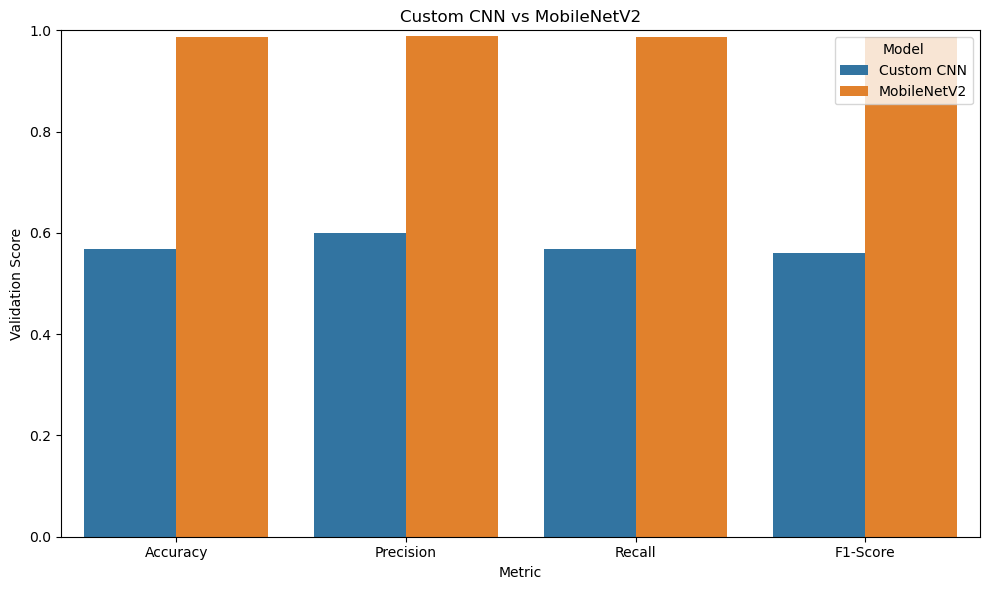

In [57]:
comparison_plot = comparison_df.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("Custom CNN vs MobileNetV2")
plt.ylabel("Validation Score")
plt.tight_layout()
plt.show()

# Select the best-performing model

In [58]:
if mobilenet_f1 > f1:
    best_model = transfer_model
    best_model_name = "MobileNetV2"
    best_predictions = mobilenet_pred
    best_probabilities = mobilenet_prob
    best_f1 = mobilenet_f1
else:
    best_model = cnn_model
    best_model_name = "Custom CNN"
    best_predictions = y_pred
    best_probabilities = y_prob
    best_f1 = f1

print("Selected model:", best_model_name)
print("Macro F1-score:", round(best_f1, 4))
print("Selection criterion: Highest validation macro F1-score")

Selected model: MobileNetV2
Macro F1-score: 0.9875
Selection criterion: Highest validation macro F1-score


# Save the selected model

In [60]:
import os

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

best_model_path = MODEL_DIR / "best_image_classification_model.keras"

best_model.save(best_model_path)

print("Best model saved successfully!")
print("Selected model:", best_model_name)
print("Model location:", best_model_path)
print("File size:",
      round(best_model_path.stat().st_size / (1024 * 1024), 2),
      "MB")

Best model saved successfully!
Selected model: MobileNetV2
Model location: C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\best_image_classification_model.keras
File size: 11.09 MB


In [61]:
import json

mapping_path = MODEL_DIR / "class_mapping.json"

with open(mapping_path, "w") as file:
    json.dump(class_mapping, file, indent=4)

print("Class mapping saved successfully!")
print("Location:", mapping_path)

Class mapping saved successfully!
Location: C:\Users\prana\Project For ML\PRAICP-1010-Image classification with 10 categories\models\class_mapping.json


In [62]:
loaded_model = keras.models.load_model(
    best_model_path
)

print("Saved model loaded successfully!")
print("Model name:", loaded_model.name)

Saved model loaded successfully!
Model name: MobileNetV2_Transfer_Learning


# Create a reusable prediction function

In [63]:
def predict_image(image_path, model=loaded_model):

    # Load image
    img = keras.utils.load_img(
        image_path,
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        color_mode="rgb"
    )

    # Convert image into array
    img_array = keras.utils.img_to_array(img)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict probabilities
    probabilities = model.predict(img_array, verbose=0)[0]

    # Get predicted class
    predicted_index = int(np.argmax(probabilities))

    category_id = class_names[predicted_index]
    predicted_category = class_mapping[category_id]

    confidence = float(probabilities[predicted_index])

    return {
        "Predicted Category": predicted_category,
        "Confidence": round(confidence * 100, 2),
        "Category ID": category_id
    }

print("Prediction function created successfully!")

Prediction function created successfully!


### Test with a validation image

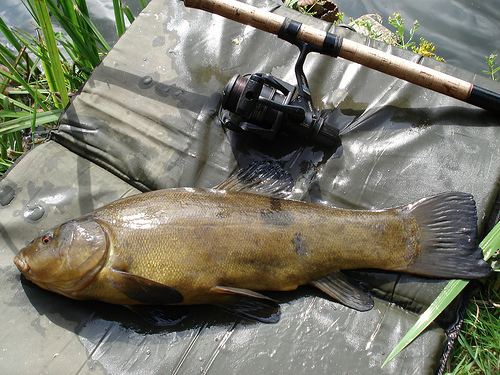

Prediction Result:
{'Predicted Category': 'Tench', 'Confidence': 100.0, 'Category ID': 'n01440764'}


In [64]:
sample_image_path = image_df.loc[
    image_df["Split"] == "Validation",
    "Image_Path"
].iloc[0]

result = predict_image(sample_image_path)

display(Image.open(sample_image_path).convert("RGB"))

print("Prediction Result:")
print(result)

In [66]:
original_prediction = best_model.predict(
    np.expand_dims(
        keras.utils.img_to_array(
            keras.utils.load_img(
                sample_image_path,
                target_size=(IMG_HEIGHT, IMG_WIDTH)
            )
        ),
        axis=0
    ),
    verbose=0
)

reloaded_prediction = loaded_model.predict(
    np.expand_dims(
        keras.utils.img_to_array(
            keras.utils.load_img(
                sample_image_path,
                target_size=(IMG_HEIGHT, IMG_WIDTH)
            )
        ),
        axis=0
    ),
    verbose=0
)

difference = np.max(
    np.abs(original_prediction - reloaded_prediction)
)

print("Maximum prediction difference:", difference)
print("Model reload verification completed!")

Maximum prediction difference: 0.0
Model reload verification completed!
